<a href="https://colab.research.google.com/github/likhithapotluri/AAI_521/blob/main/AAI_521_Likhitha_Assignment1_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1.1 – Image Processing and Neural Networks
**Name:** Likhitha Potluri&nbsp;|&nbsp; **Course:** AAI-521

This notebook was run on Google Colab (TensorFlow 2.21.0, OpenCV 4.14.0, Pillow 11.3.0).

**Part 1- Neural Network**

In [ ]:
import numpy as np
import os
import pathlib
import PIL
import PIL.Image
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
from tensorflow.keras.datasets import fashion_mnist

print("TensorFlow version:", tf.__version__)
print("OpenCV version:", cv2.__version__)
print("Pillow version:", PIL.__version__)

TensorFlow version: 2.21.0
OpenCV version: 4.14.0
Pillow version: 11.3.0


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (60000, 28, 28)  Training labels: (60000,)
Test data:     (10000, 28, 28)  Test labels:     (10000,)


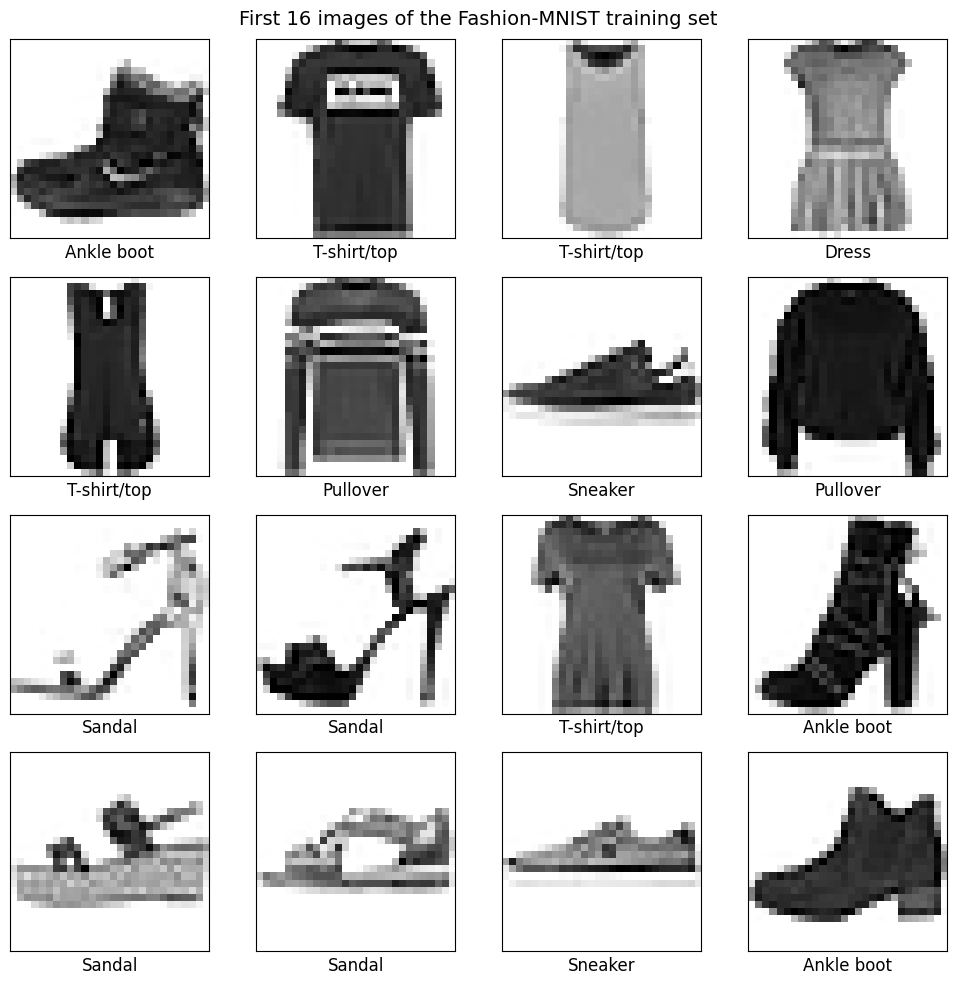

In [ ]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()   # Load the dataset
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']   # Labels

print("Training data:", X_train.shape, " Training labels:", y_train.shape)
print("Test data:    ", X_test.shape, " Test labels:    ", y_test.shape)

# Draw the first 16 training images with the label (name) under each image
plt.figure(figsize=(10, 10))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(X_train[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[y_train[i]], fontsize=12)
plt.suptitle("First 16 images of the Fashion-MNIST training set", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# Images are 28x28. We don't plan to resize them now
IMG_HEIGHT = 28
IMG_WIDTH = 28

In [ ]:
# Normalize inputs from 0-255 to 0-1 (both train and test)
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

print("Train pixel range:", X_train.min(), "to", X_train.max())
print("Test pixel range: ", X_test.min(), "to", X_test.max())

Train pixel range: 0.0 to 1.0
Test pixel range:  0.0 to 1.0


In [ ]:
# NN model with one hidden layer (128 nodes) and ReLU activation.
# Output activation: SOFTMAX. There are 10 mutually exclusive classes, and softmax turns
# the 10 outputs into class probabilities that add up to 1.

loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()   # labels are integers 0-9 (not one-hot)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH)),
    tf.keras.layers.Flatten(),                         # 28x28 -> 784 vector
    tf.keras.layers.Dense(128, activation='relu'),     # hidden layer
    tf.keras.layers.Dense(10, activation='softmax')    # output layer
])

model.compile(
    optimizer='adam',
    loss=loss_fn,
    metrics=['accuracy']
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

**What should be the output activation function?**

The output layer should use **Softmax** with **10 neurons**, one per clothing class. This is a multi-class, single-label problem: each image belongs to exactly one class. Softmax turns the raw scores (logits) into a probability distribution that adds up to 1, and the predicted class is the one with the highest probability. Sigmoid would treat each class independently, which suits multi-label problems, not this one. Softmax pairs with **sparse categorical cross-entropy** because the labels are integers (0–9).

In [ ]:
# Train the model: 20% validation, 20 epochs, batch size 128
hist = model.fit(X_train, y_train,
                 validation_split=0.2,
                 epochs=20,
                 batch_size=128,
                 verbose=1)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest accuracy: {test_acc:.4f}   Test loss: {test_loss:.4f}")

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8014 - loss: 0.5752 - val_accuracy: 0.8488 - val_loss: 0.4341
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8559 - loss: 0.4128 - val_accuracy: 0.8595 - val_loss: 0.3974
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8678 - loss: 0.3707 - val_accuracy: 0.8635 - val_loss: 0.3814
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8759 - loss: 0.3434 - val_accuracy: 0.8725 - val_loss: 0.3595
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8844 - loss: 0.3238 - val_accuracy: 0.8722 - val_loss: 0.3564
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8875 - loss: 0.3091 - val_accuracy: 0.8786 - val_loss: 0.3309
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8928 - loss: 0.2928 - val_accuracy: 0.8800 - val_loss: 0.3386
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8980 - loss: 0.2807 - val_accuracy: 0.

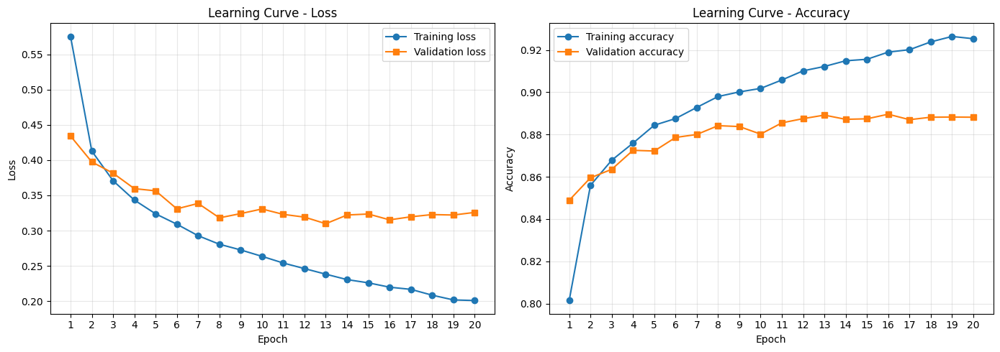

Lowest validation loss : 0.3099 at epoch 13
Final validation loss  : 0.3259
Final training accuracy: 0.9253
Final validation acc.  : 0.8882
Train-validation accuracy gap at the end: 0.0371


In [ ]:
# Draw the learning curves
h = hist.history
epochs_range = range(1, len(h['loss']) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, h['loss'], 'o-', label='Training loss')
plt.plot(epochs_range, h['val_loss'], 's-', label='Validation loss')
plt.title('Learning Curve - Loss')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.xticks(epochs_range); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, h['accuracy'], 'o-', label='Training accuracy')
plt.plot(epochs_range, h['val_accuracy'], 's-', label='Validation accuracy')
plt.title('Learning Curve - Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.xticks(epochs_range); plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_ep = int(np.argmin(h['val_loss'])) + 1
print(f"Lowest validation loss : {min(h['val_loss']):.4f} at epoch {best_ep}")
print(f"Final validation loss  : {h['val_loss'][-1]:.4f}")
print(f"Final training accuracy: {h['accuracy'][-1]:.4f}")
print(f"Final validation acc.  : {h['val_accuracy'][-1]:.4f}")
print(f"Train-validation accuracy gap at the end: {h['accuracy'][-1] - h['val_accuracy'][-1]:.4f}")

**Understanding of the learning curves**

- **Early epochs (1–5):** training and validation loss both fall quickly (validation loss goes from 0.43 to about 0.36), and both accuracies rise together. The network is learning general features, such as the outline and shape of each garment, that also work on unseen images. In epochs 1–3, validation accuracy is even *higher* than training accuracy. That happens because Keras reports training accuracy as an average across the epoch while the weights are still changing, but measures validation accuracy at the end of the epoch.
- **Middle epochs (6–13):** the curves separate. Training loss keeps falling steadily, but validation loss stops improving and stays flat at about 0.31–0.33. It reaches its **lowest value of 0.3099 at epoch 13**.
- **Later epochs (14–20):** training loss keeps dropping (from 0.24 to 0.20) and training accuracy climbs to **92.53%**. Validation loss creeps slightly upward to **0.3259**, and validation accuracy stays flat at about **88.8%**. The train–validation accuracy gap grows from almost zero at epoch 3 to **3.71%** at epoch 20. Test accuracy (**88.02%**) is close to validation accuracy, which confirms the validation curve reflects real performance on unseen data.

**Diagnosis: the model is overfitting, mildly but clearly.** From about epoch 8 on, extra training only improves results on the training set. The network starts memorizing details and noise in the training images instead of learning patterns that generalize. That shows in the **widening gap**: training loss keeps falling while validation loss is flat or rising. It isn't severe yet (validation accuracy doesn't collapse), but the last 7–12 epochs add nothing useful. Reasons:
1. The model has 101,770 trainable parameters and nothing to restrain it (no dropout, no weight penalty, no early stopping).
2. A dense network flattens the 28×28 image into a 784-length vector and loses spatial structure. It learns pixel positions instead of features like edges and textures, and those don't transfer well.
3. Some classes look very similar (Shirt vs T-shirt/top vs Pullover vs Coat). The model fits the training examples of these classes too closely, but can't separate them on new images. This is why validation accuracy stalls at about 89%.

**Suggestions to resolve the issue**
1. **Early stopping:** monitor `val_loss` and keep the weights from the best epoch (epoch 13 here) instead of training to epoch 20.
2. **Dropout:** add a Dropout layer (rate 0.2–0.5) after the hidden layer so neurons can't co-adapt.
3. **L2 (weight-decay) regularization** on the Dense layer to keep weights small.
4. **Data augmentation** (small shifts, rotations, flips) to give the model more varied training data.
5. **Use a CNN:** convolution and pooling layers keep spatial information and share weights. They usually reach about 91–93% on Fashion-MNIST and do better on the confusable classes.
6. **Lower the learning rate or use a schedule** (e.g. ReduceLROnPlateau) so the later epochs fine-tune gently.

The next cell tests suggestions 1 and 2.

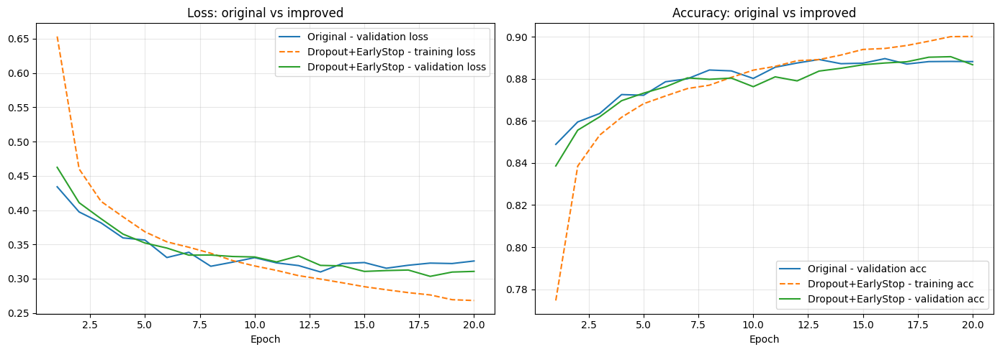

Improved model stopped after 20 epochs
Original model test accuracy: 0.8802
Improved model test accuracy: 0.8813
Improved model train-val gap: 0.0135


In [ ]:
# Testing the suggested fix: Dropout + EarlyStopping
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation='softmax')
])
model2.compile(optimizer='adam', loss=loss_fn, metrics=['accuracy'])

early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3,
                                              restore_best_weights=True)
hist2 = model2.fit(X_train, y_train, validation_split=0.2, epochs=20,
                   batch_size=128, callbacks=[early_stop], verbose=0)
h2 = hist2.history

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, len(h['val_loss'])+1), h['val_loss'], label='Original - validation loss')
plt.plot(range(1, len(h2['loss'])+1), h2['loss'], '--', label='Dropout+EarlyStop - training loss')
plt.plot(range(1, len(h2['val_loss'])+1), h2['val_loss'], label='Dropout+EarlyStop - validation loss')
plt.title('Loss: original vs improved'); plt.xlabel('Epoch'); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, len(h['val_accuracy'])+1), h['val_accuracy'], label='Original - validation acc')
plt.plot(range(1, len(h2['accuracy'])+1), h2['accuracy'], '--', label='Dropout+EarlyStop - training acc')
plt.plot(range(1, len(h2['val_accuracy'])+1), h2['val_accuracy'], label='Dropout+EarlyStop - validation acc')
plt.title('Accuracy: original vs improved'); plt.xlabel('Epoch'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

test_acc2 = model2.evaluate(X_test, y_test, verbose=0)[1]
print("Improved model stopped after", len(h2['loss']), "epochs")
print(f"Original model test accuracy: {test_acc:.4f}")
print(f"Improved model test accuracy: {test_acc2:.4f}")
print(f"Improved model train-val gap: {h2['accuracy'][-1] - h2['val_accuracy'][-1]:.4f}")

**Result of the fix**

| Metric | Original model | Dropout + Early Stopping |
|---|---|---|
| Train–validation accuracy gap | 3.71% | **1.35%** |
| Test accuracy | 88.02% | **88.13%** |
| Epochs trained | 20 | 20 |

- **Dropout reduced the overfitting.** The train–validation gap fell from 3.71% to 1.35%, about 64% smaller. In the comparison plot, the dropout model's training and validation curves stay close for all 20 epochs instead of pulling apart. Dropout randomly switches off 30% of the hidden neurons on each training step, so the network can't depend on specific neurons to memorize images and has to learn more robust features.
- **One caveat:** the dropout model's training accuracy is measured *while dropout is on* (the network is handicapped during training). That makes training accuracy look lower and the 1.35% gap look a bit smaller than it really is. Even so, the validation curves give the honest comparison. The dropout model's validation loss keeps going down to about 0.30 at epoch 18, while the original model's levels off and creeps up after epoch 13.
- **Early stopping never triggered.** Validation loss kept reaching new lows (the last one at epoch 18), so there were never 3 epochs in a row without improvement. Almost all of the improvement comes from dropout. Early stopping acted only as a safety net, and its patience of 3 is too short to judge the 19–20 epoch range.
- **Test accuracy improved only slightly** (+0.11 points). That is expected. Regularization mainly makes a model **more reliable** (it generalizes more consistently and doesn't drift with longer training), not much more accurate. Since the dropout model's validation loss was still improving, it could probably train a few more epochs.
- **Conclusion:** overfitting was the problem, and dropout fixed it. But a single 128-neuron dense layer seems capped at about 88% test accuracy because it ignores spatial structure. To get clearly higher accuracy, the next step is a **CNN** with augmentation, which can learn the edge and texture features needed to separate Shirt, T-shirt, Pullover and Coat.

**Part 2- Image Processing (TensorFlow)**

Load the Flower photo dataset from the TensorFlow repository.

In [ ]:
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive = tf.keras.utils.get_file("flower_photos.tgz", origin=dataset_url, extract=True)

# Search the Keras datasets folder (newer Keras versions extract into a nested folder)
search_root = pathlib.Path(archive).parent

# Find the folder that directly contains the flower-class folders
daisy_folders = [folder for folder in search_root.rglob("daisy") if folder.is_dir()]
if not daisy_folders:
    raise FileNotFoundError("The extracted daisy folder could not be found.")

data_dir = daisy_folders[0].parent
image_count = len(list(data_dir.glob("*/*.jpg")))

# Print the number of images and the classes
print("Data directory:", data_dir)
print("Total number of images:", image_count)
flower_classes = sorted([d.name for d in data_dir.iterdir() if d.is_dir()])
print("Classes (subfolders):", flower_classes)
for c in flower_classes:
    print(f"   {c:<11}: {len(list(data_dir.glob(c + '/*.jpg')))} images")

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Data directory: /root/.keras/datasets/flower_photos_extracted/flower_photos
Total number of images: 3670
Classes (subfolders): ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
   daisy      : 633 images
   dandelion  : 898 images
   roses      : 641 images
   sunflowers : 699 images
   tulips     : 799 images


*a) How many images we can find in this dataset?*

The dataset has **3,670 images** in **5 subfolders (classes)**: daisy (633), dandelion (898), roses (641), sunflowers (699) and tulips (799). The classes are somewhat **imbalanced**: dandelion has about 40% more images than daisy. A model could lean slightly toward the bigger classes, so per-class accuracy should be checked, not only overall accuracy.

*b) The list of subfolders are:*
*   daisy
*   dandelion
*   roses
*   sunflowers
*   tulips

Use Pillow (PIL) to show at least one flower from each subfolder.

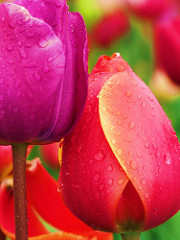

In [ ]:
tulips = list(data_dir.glob('tulips/*'))    # list of files in the tulips subfolder
PIL.Image.open(str(tulips[14]))              # Pillow displays the image

daisy       -> 100080576_f52e8ee070_n.jpg     size=(320, 263)  mode=RGB
dandelion   -> 10043234166_e6dd915111_n.jpg   size=(320, 213)  mode=RGB
roses       -> 10090824183_d02c613f10_m.jpg   size=(179, 240)  mode=RGB
sunflowers  -> 1008566138_6927679c8a.jpg      size=(500, 330)  mode=RGB
tulips      -> 100930342_92e8746431_n.jpg     size=(320, 209)  mode=RGB


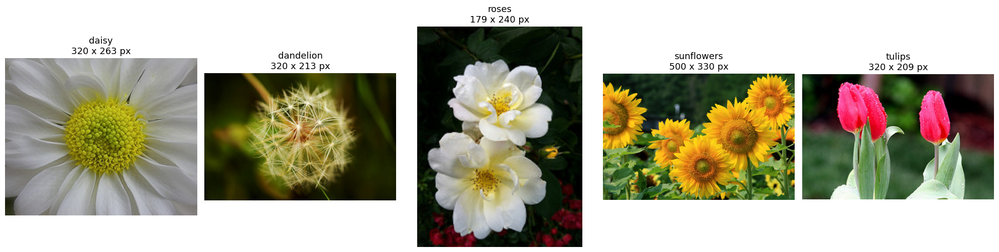

In [ ]:
# Use Pillow to open one flower from EACH subfolder
flower_classes = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
plt.figure(figsize=(20, 5))
for i, flower in enumerate(flower_classes):
    img_path = sorted(data_dir.glob(f'{flower}/*'))[0]
    img = PIL.Image.open(str(img_path))              # opened with PIL
    plt.subplot(1, 5, i + 1)
    plt.imshow(img)
    plt.title(f"{flower}\n{img.size[0]} x {img.size[1]} px", fontsize=13)
    plt.axis('off')
    print(f"{flower:<11} -> {img_path.name:<30} size={img.size}  mode={img.mode}")
plt.tight_layout()
plt.show()

The printed sizes show that the images have **different dimensions**. That's a problem for a neural network, which needs a fixed input shape, so part (c) resizes every image to 180×180.

*c) Use Keras to resize all the images into same dimension 180x180*

In [ ]:
batch_size = 32
img_height = 180
img_width = 180

In [ ]:
# Training data (80%) resized to 180x180
train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.


In [ ]:
# Validation data (20%) resized to 180x180
val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

for images, labels in val_ds.take(1):
    print("Validation batch shape:", images.shape)   # (32, 180, 180, 3)
    print("Label batch shape:     ", labels.shape)
print("Classes:", val_ds.class_names)

Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Validation batch shape: (32, 180, 180, 3)
Label batch shape:      (32,)
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


**Message from Python:** *"Found 3670 files belonging to 5 classes. Using 734 files for validation."* (and *"Using 2936 files for training."* for train_ds).

Keras worked out **5 classes** automatically from the subfolder names, in alphabetical order: daisy=0, dandelion=1, roses=2, sunflowers=3, tulips=4. It resized every image to **180×180×3** whatever its original size, and grouped them into batches of 32. Both subsets use the same `seed=123` and `validation_split=0.2`, so the 80/20 split doesn't overlap: no validation image is in the training set.

d) *Use* `train_ds.class_names` *to get the list of labels, and randomly show 9 images from the training data with their label on top of each image.*

Labels: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


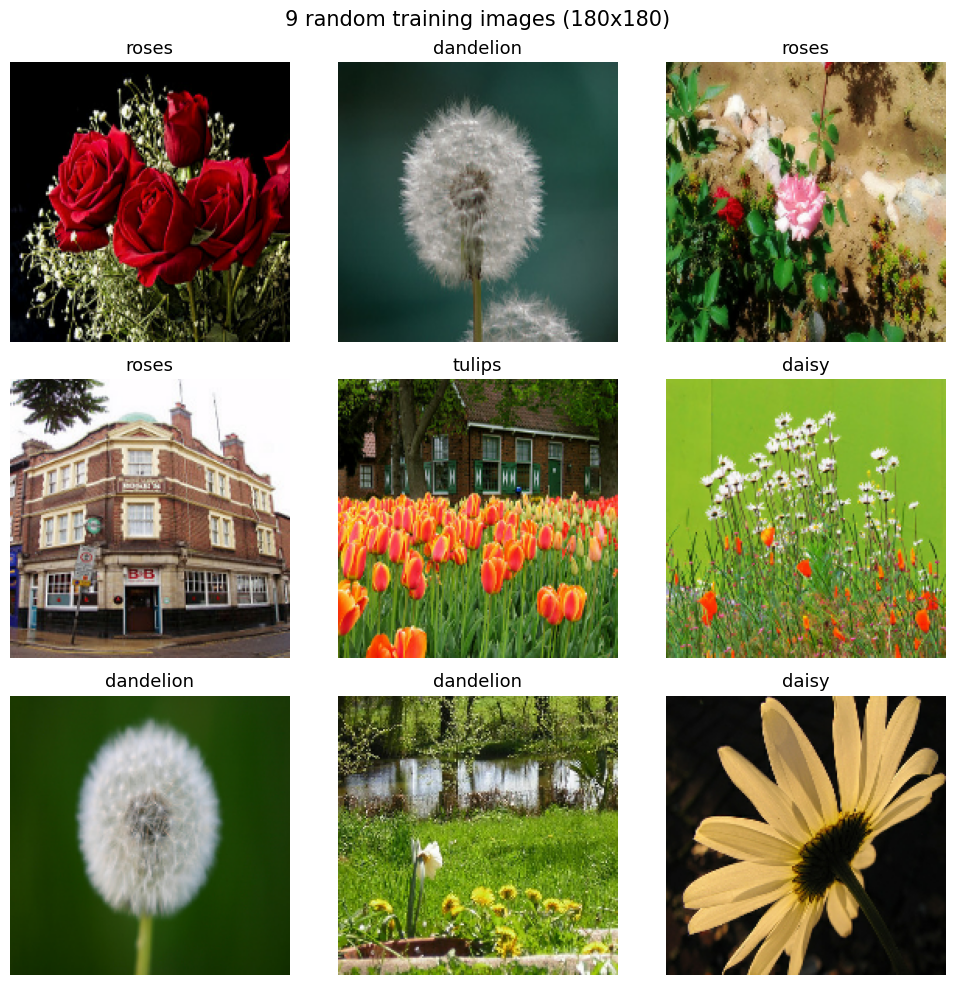

In [ ]:
class_names = train_ds.class_names
print("Labels:", class_names)

plt.figure(figsize=(10, 10))
for images, labels in train_ds.shuffle(100).take(1):   # random batch
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]], fontsize=13)
        plt.axis("off")
plt.suptitle("9 random training images (180x180)", fontsize=15)
plt.tight_layout()
plt.show()

**Barriers to proper classification seen in the images**

Looking closely at the 9 random training images above:

1. **Label noise / irrelevant images:** one image labeled **"roses" is actually a brick building** (a B&B pub). Any rose in it is tiny or not visible at all. Images like this teach the model wrong associations ("brick walls → roses").
2. **Different growth stages under one label:** two of the **"dandelion"** images show the white, fluffy **seed head**, not the yellow flower. These look nothing like the yellow dandelions in the other dandelion image, so one class covers two very different appearances.
3. **Several flower types in one image:** the **"daisy"** image with a lime-green background also has **orange poppies**. The model can't tell which flower the label refers to.
4. **Cluttered backgrounds:** the **"tulips"** image has a house with windows behind the flowers. The third "dandelion" image is mostly grass, a pond and trees, and the flowers are small. The model may learn the scenery (grass, buildings) instead of the flower.
5. **Different scale and framing:** some images are extreme close-ups that fill the frame (the dandelion seed heads, the yellowish daisy), and others show a whole field or scene where the flower takes up only a small part.
6. **Lighting and color variation:** the roses bouquet is on a **black background** and another daisy is in a dark scene, while the other images are brightly lit outdoors. One "daisy" looks cream/yellow instead of white. Color alone isn't reliable.
7. **Similar-looking classes:** daisy, sunflower and dandelion all have a central disc with surrounding petals, and roses and tulips share the same colors (red, pink, yellow).
8. **Distortion from resizing:** every image is forced to 180×180 whatever its original aspect ratio (e.g. 500×330, 179×240 in part b). That stretches or squashes flowers and changes their natural shape.
9. **Class imbalance:** dandelion (898 images) has about 40% more than daisy (633), which can bias predictions.

To deal with these: clean up mislabeled images, use **data augmentation** (part e) for scale and viewpoint, and use a **CNN** (ideally pretrained, via transfer learning) that learns features that work wherever the flower is in the image.

*e) Use the preprocessing package in Keras to apply different filters to the image:*
- *Rescale the image by dividing by 255*
- *Shear the image 20%*
- *Zoom the image 20%*
- *Horizontally flip the images*

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,          # rescale pixel values to 0-1
    shear_range=0.2,         # shear 20%
    zoom_range=0.2,          # zoom 20%
    horizontal_flip=True)    # random horizontal flip

training_set = train_datagen.flow_from_directory(data_dir,
                                                 target_size=(180, 180),
                                                 batch_size=32,
                                                 class_mode='sparse')
print("Class indices:", training_set.class_indices)

Found 3670 images belonging to 5 classes.
Class indices: {'daisy': 0, 'dandelion': 1, 'roses': 2, 'sunflowers': 3, 'tulips': 4}


Batch shape: (32, 180, 180, 3)  Pixel range: 0.0 to 1.0


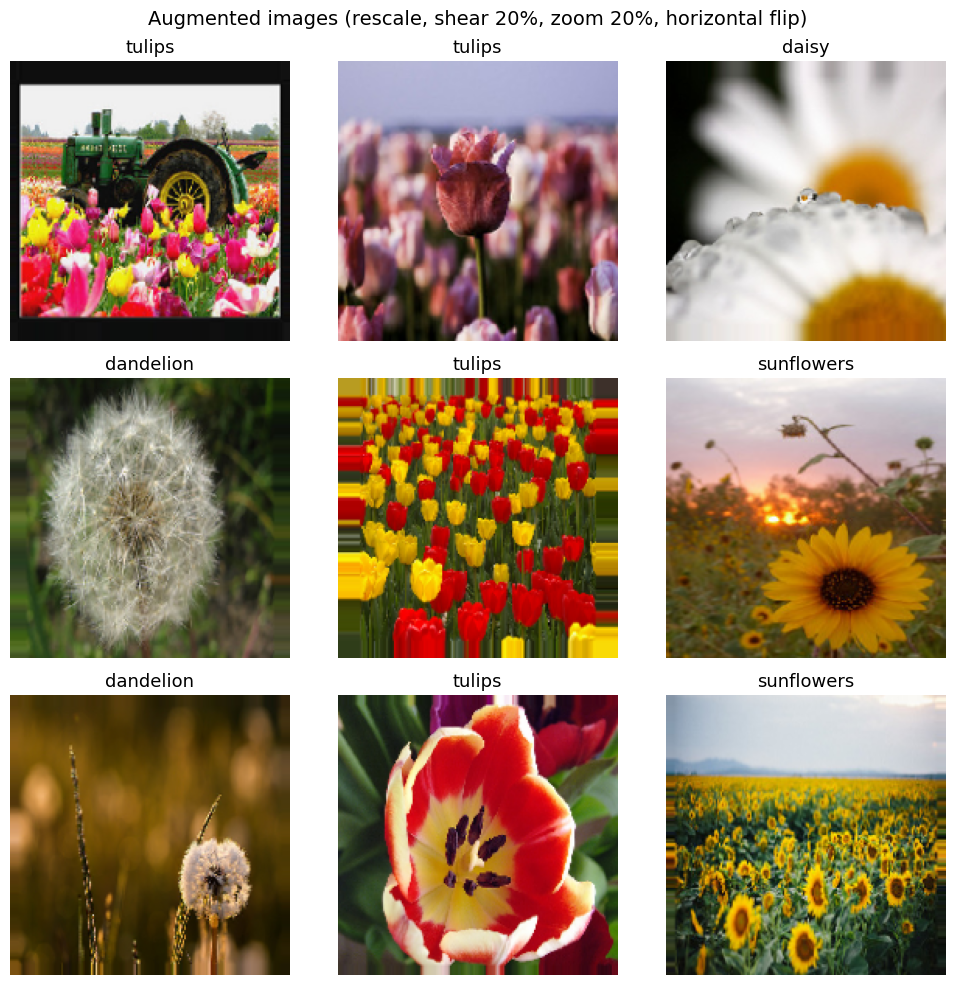

In [ ]:
# Show 9 augmented images from the generator
idx_to_class = {v: k for k, v in training_set.class_indices.items()}
aug_images, aug_labels = next(training_set)
print("Batch shape:", aug_images.shape, " Pixel range:",
      round(float(aug_images.min()), 3), "to", round(float(aug_images.max()), 3))

plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(aug_images[i])          # already 0-1, so no uint8 conversion needed
    plt.title(idx_to_class[int(aug_labels[i])], fontsize=13)
    plt.axis('off')
plt.suptitle("Augmented images (rescale, shear 20%, zoom 20%, horizontal flip)", fontsize=14)
plt.tight_layout()
plt.show()

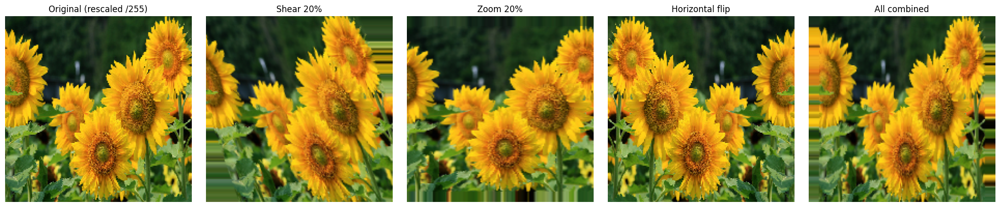

In [ ]:
# Effect of each filter on ONE image
sample_path = str(sorted(data_dir.glob('sunflowers/*'))[0])
sample = tf.keras.utils.img_to_array(tf.keras.utils.load_img(sample_path, target_size=(180, 180)))
sample = np.expand_dims(sample, 0)

filters = {
    "Original (rescaled /255)": ImageDataGenerator(rescale=1./255),
    "Shear 20%":                ImageDataGenerator(rescale=1./255, shear_range=0.2),
    "Zoom 20%":                 ImageDataGenerator(rescale=1./255, zoom_range=0.2),
    "Horizontal flip":          ImageDataGenerator(rescale=1./255, horizontal_flip=True),
    "All combined":             train_datagen,
}

plt.figure(figsize=(20, 4))
for i, (name, gen) in enumerate(filters.items()):
    if name == "Horizontal flip":
        out = gen.standardize(np.flip(sample.copy(), axis=2))[0]   # flip shown deterministically
    elif name == "Shear 20%":
        out = gen.apply_transform(sample[0].copy(), {'shear': 20}) / 255.0
    else:
        out = next(gen.flow(sample.copy(), batch_size=1, seed=7))[0]
    plt.subplot(1, 5, i + 1)
    plt.imshow(np.clip(out, 0, 1))
    plt.title(name, fontsize=12)
    plt.axis('off')
plt.tight_layout()
plt.show()

**Effect and purpose of each filter**

- **Rescale (1/255):** pixel values go from 0–255 to 0–1, as the printed range confirms (0.0 to 1.0). The image looks the same, but small input values keep gradient-based training stable.
- **Shear 20%:** slants the image sideways, as if the flower were photographed from an angle.
- **Zoom 20%:** randomly zooms in or out by up to 20%, so the flowers look closer or farther away.
- **Horizontal flip:** mirrors the image left to right. A mirrored sunflower is still a sunflower.

**Observation:** in the shear, zoom and combined images, the edges show **streaks**. Shearing or zooming out leaves empty pixels, and Keras fills them by repeating the nearest edge pixel (`fill_mode='nearest'` by default). These artifacts are unrealistic, so keep augmentation strength moderate or use `fill_mode='reflect'`.

**Why this helps:** each epoch, the model sees new, realistic versions of every training image. This directly addresses barriers from part (d) (different scale, viewpoint and orientation), effectively enlarges a small dataset of 3,670 images, and reduces overfitting. Augmentation should only be used on the **training** data. Validation and test data should only be rescaled, so evaluation reflects real, unmodified images.

**Part 3- OpenCV**

a) Show the first 9 images in the dataset using OpenCV. Resize each image to 180x180 before showing it.

Total images found: 3670


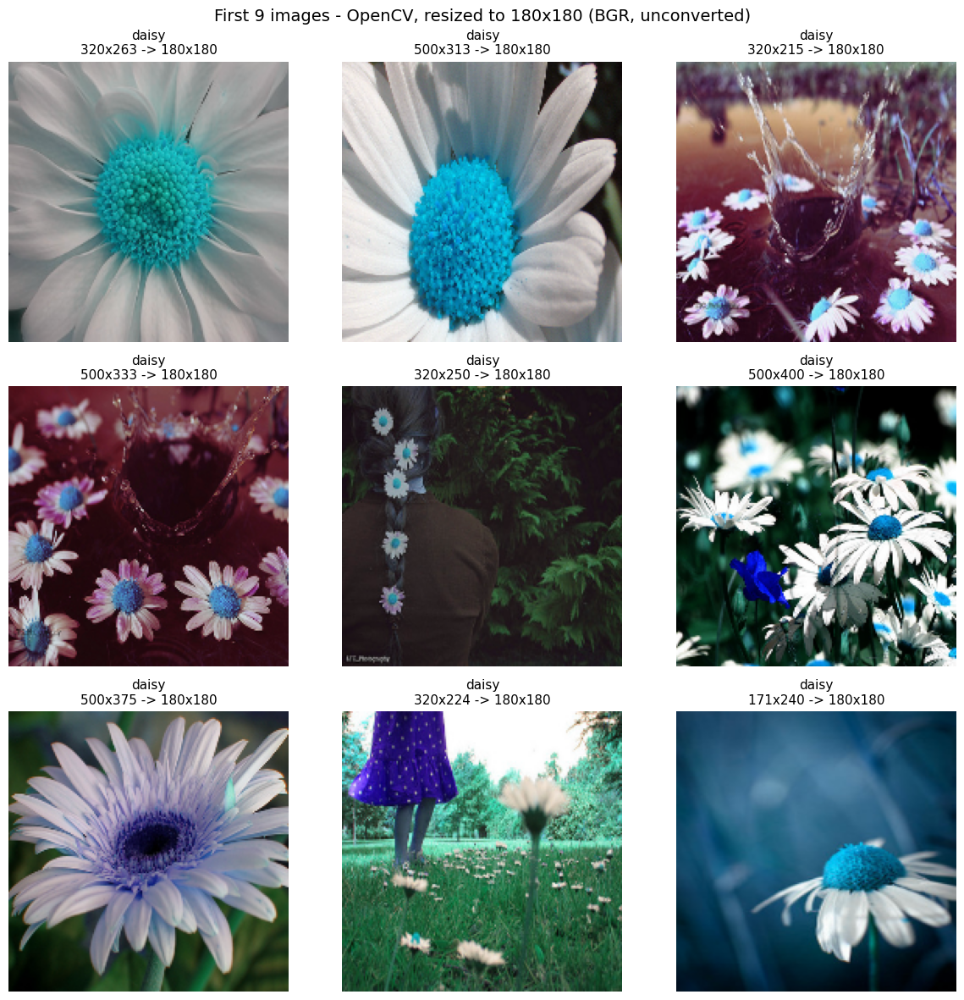

In [ ]:
list_of_images = sorted(data_dir.glob('*/*.jpg'))
print("Total images found:", len(list_of_images))

fig = plt.figure(figsize=(12, 12))
for i in range(9):
    img = cv2.imread(str(list_of_images[i]))          # OpenCV reads the image (BGR order)
    original_shape = img.shape
    img = cv2.resize(img, (180, 180))                  # resize to 180x180
    ax = plt.subplot(3, 3, i + 1)
    ax.imshow(img)                                     # shown as-is (BGR)
    ax.set_title(f"{list_of_images[i].parent.name}\n{original_shape[1]}x{original_shape[0]} -> {img.shape[1]}x{img.shape[0]}",
                 fontsize=11)
    ax.axis('off')
plt.suptitle("First 9 images - OpenCV, resized to 180x180 (BGR, unconverted)", fontsize=14)
plt.tight_layout()
plt.show()

**Observation:** the colors above are wrong. The first 9 images (all from the *daisy* folder, which comes first alphabetically) show the daisies' **yellow centers as bright cyan/blue**, the **red poppy as dark blue**, and a **red dress as purple/blue**. The white petals look about right, because white has equal R, G and B values and swapping channels doesn't change it.

**Why:** **OpenCV loads images in BGR order** (Blue, Green, Red), but **matplotlib expects RGB**. Without conversion, the red and blue channels are swapped, so red/yellow areas turn blue/cyan. The fix is to convert from BGR to RGB with `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)`.

b) Convert the images to normal (natural) coloring.

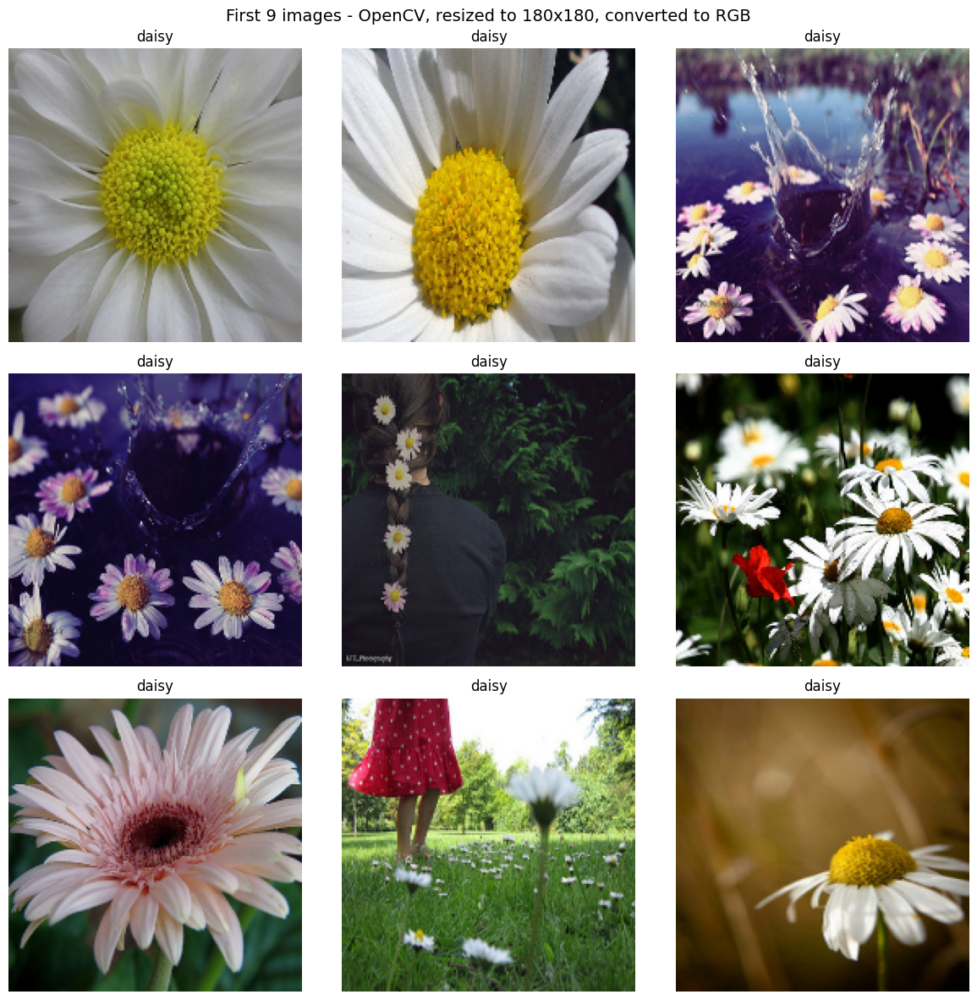

In [ ]:
fig = plt.figure(figsize=(12, 12))
for i in range(9):
    img = cv2.imread(str(list_of_images[i]))
    img = cv2.resize(img, (180, 180))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)         # BGR -> RGB for natural colors
    ax = plt.subplot(3, 3, i + 1)
    ax.imshow(img)
    ax.set_title(list_of_images[i].parent.name, fontsize=12)
    ax.axis('off')
plt.suptitle("First 9 images - OpenCV, resized to 180x180, converted to RGB", fontsize=14)
plt.tight_layout()
plt.show()

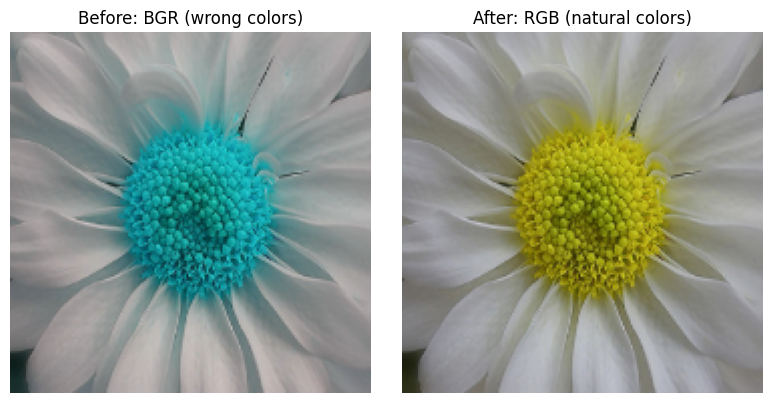

Pixel [90,90] in BGR: [ 8 71 73]   in RGB: [73 71  8]  -> first and last channels swapped


In [ ]:
# Side-by-side comparison for one image: BGR vs RGB
img_bgr = cv2.resize(cv2.imread(str(list_of_images[0])), (180, 180))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(img_bgr); plt.title("Before: BGR (wrong colors)"); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(img_rgb); plt.title("After: RGB (natural colors)"); plt.axis('off')
plt.tight_layout(); plt.show()

print("Pixel [90,90] in BGR:", img_bgr[90, 90], "  in RGB:", img_rgb[90, 90], " -> first and last channels swapped")

After `cv2.COLOR_BGR2RGB`, the images show their natural colors: **yellow daisy centers, a red poppy, a red polka-dot dress, and green grass and leaves**. The printed pixel confirms what happened: **BGR [8, 71, 73] became RGB [73, 71, 8]**. Only the first and last channels swapped. The pixel data itself didn't change.

This matters for modeling: a model trained on RGB images (like the Keras pipeline in Part 2) must be given RGB images at prediction time. Feeding it BGR images straight from OpenCV would quietly hurt accuracy, because colors like yellow and red are the strongest clues for telling sunflowers, dandelions and roses apart.

**Note:** these first 9 images also show the label-noise problem from part (d). The pink flower in the bottom-left is a **gerbera**, not a true daisy, but it's stored in the *daisy* folder.

This part onward creates a PDF from this ipynb file.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!apt-get install texlive texlive-xetex texlive-latex-extra pandoc
!pip install pypandoc

In [ ]:
%shell jupyter nbconvert --to pdf '/content/drive/MyDrive/AAI_521_Likhitha_Assignment1_1.ipynb'